# Likelihood-based estimation of diffusion strength

This notebook simulates two stochastic differential equations (SDEs) and estimates their diffusion strength $\sigma$ by maximum likelihood.

1. Brownian motion: $dX_t = \sigma\,dW_t$.
2. A noisy harmonic oscillator: $dX_t=V_t\,dt$, $dV_t=-\omega_0^2X_t\,dt+\sigma\,dW_t$.

Throughout, $W_t$ is standard Brownian motion and observations are equally spaced by $\Delta t$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

plt.style.use("seaborn-v0_8-whitegrid")
rng = np.random.default_rng(seed=1)

## 1. Brownian motion

For $dX_t = \sigma\,dW_t$, an Euler--Maruyama step is

$$X_{i+1}=X_i+\sigma\sqrt{\Delta t}Z_i, \qquad Z_i\stackrel{\mathrm{iid}}{\sim}N(0,1).$$

Thus the increments $\Delta X_i=X_{i+1}-X_i$ are independent with $\Delta X_i\sim N(0,\sigma^2\Delta t)$.

In [2]:
def brownian_motion(x0, sigma, dt, n_steps, rng):
    """Simulate dX_t = sigma dW_t by Euler--Maruyama."""
    increments = sigma * np.sqrt(dt) * rng.normal(size=n_steps)
    return np.arange(n_steps + 1) * dt, np.r_[x0, x0 + np.cumsum(increments)]

brownian_dt = 0.02
brownian_n_steps = 2_000
brownian_sigma_true = 0.8

paths_list = []
for i in range(300):
    brownian_time, brownian_path = brownian_motion(
        x0=0.0, sigma=brownian_sigma_true, dt=brownian_dt,
        n_steps=brownian_n_steps, rng=rng,
    )
    paths_list.append((brownian_time, brownian_path))

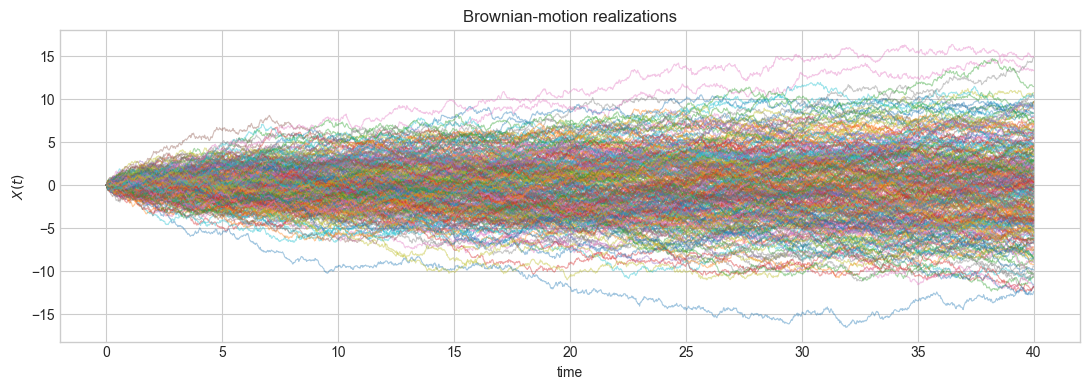

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
for time, path in paths_list:
    ax.plot(time, path, lw=0.8, alpha=0.4)
ax.set(title="Brownian-motion realizations", xlabel="time", ylabel="$X(t)$")
fig.tight_layout()
plt.show()

In [4]:
endpoints_true = np.array([path[-1] for time, path in paths_list])
brownian_duration = brownian_dt * brownian_n_steps
brownian_endpoint_sigma_hat = np.sqrt(np.mean(endpoints_true**2) / brownian_duration)
print(f"Brownian endpoint estimate (T={brownian_duration:g}): {brownian_endpoint_sigma_hat:.10f}")

Brownian endpoint estimate (T=40): 0.8111029545


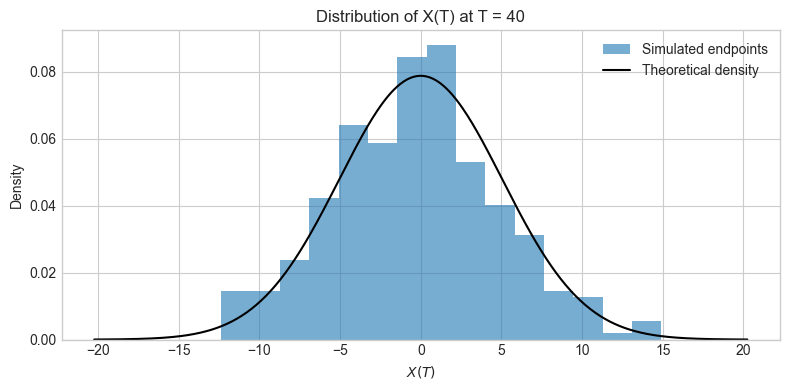

In [5]:
final_values = np.array([path[-1] for time, path in paths_list])

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(final_values, bins=15, density=True, alpha=0.6,
        label="Simulated endpoints")

# Theoretical distribution: X(T) ~ N(0, sigma² T)
brownian_duration = paths_list[0][0][-1]
std = brownian_sigma_true * np.sqrt(brownian_duration)
x = np.linspace(-4 * std, 4 * std, 400)
density = np.exp(-0.5 * (x / std)**2) / (std * np.sqrt(2 * np.pi))

ax.plot(x, density, color="black", label="Theoretical density")
ax.set(
    title=f"Distribution of X(T) at T = {brownian_duration:g}",
    xlabel="$X(T)$",
    ylabel="Density",
)
ax.legend()
fig.tight_layout()
plt.show()

### Maximum-likelihood estimate of $\sigma$

Let $y_i=\Delta X_i$. Since $y_i\sim N(0,\sigma^2\Delta t)$,

$$L(\sigma)=\prod_{i=0}^{n-1}\frac{1}{\sqrt{2\pi\sigma^2\Delta t}}\exp\left(-\frac{y_i^2}{2\sigma^2\Delta t}\right).$$

The log-likelihood is

$$\ell(\sigma)=-\frac{n}{2}\log(2\pi\sigma^2\Delta t)-\frac{1}{2\sigma^2\Delta t}\sum_{i=0}^{n-1}y_i^2.$$

Writing $v=\sigma^2$ and solving $d\ell/dv=0$ gives

$$\boxed{\widehat{\sigma}^2=\frac{1}{n\Delta t}\sum_{i=0}^{n-1}(\Delta X_i)^2,\qquad \widehat{\sigma}=\sqrt{\frac{1}{n\Delta t}\sum_{i=0}^{n-1}(\Delta X_i)^2}.}$$

In [6]:
# Estimate from the last original path, even when this cell is rerun.
brownian_increments = np.diff(paths_list[-1][1])
brownian_sigma_hat = np.sqrt(np.mean(brownian_increments**2) / brownian_dt)
_, brownian_endpoint_std = norm.fit(final_values, floc=0)
brownian_endpoint_sigma_mle = brownian_endpoint_std / np.sqrt(brownian_duration)
np.testing.assert_allclose(brownian_endpoint_sigma_mle, brownian_endpoint_sigma_hat)

print(f"True Brownian sigma: {brownian_sigma_true:.10f}")
print(f"Brownian increment estimate (last path): {brownian_sigma_hat:.10f}")
print(f"Brownian endpoint estimate (normal fit): {brownian_endpoint_sigma_mle:.10f}")

True Brownian sigma: 0.8000000000
Brownian increment estimate (last path): 0.8028452968
Brownian endpoint estimate (normal fit): 0.8111029545


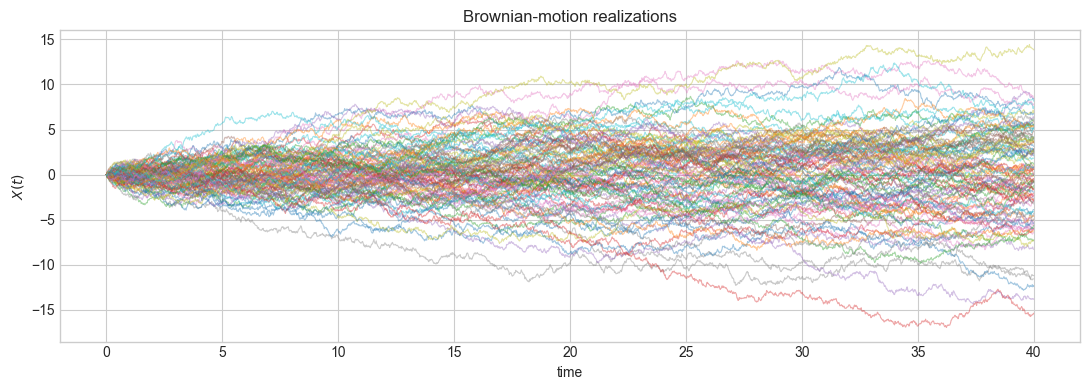

In [7]:
paths_list_sigma_hat = []
for i in range(100):
    brownian_time, brownian_path = brownian_motion(
        x0=0.0, sigma=brownian_sigma_hat, dt=brownian_dt,
        n_steps=brownian_n_steps, rng=rng,
    )
    paths_list_sigma_hat.append((brownian_time, brownian_path))


fig, ax = plt.subplots(figsize=(11, 4))
for time, path in paths_list_sigma_hat:
    ax.plot(time, path, lw=0.8, alpha=0.4)
ax.set(title="Brownian-motion realizations", xlabel="time", ylabel="$X(t)$")
fig.tight_layout()
plt.show()

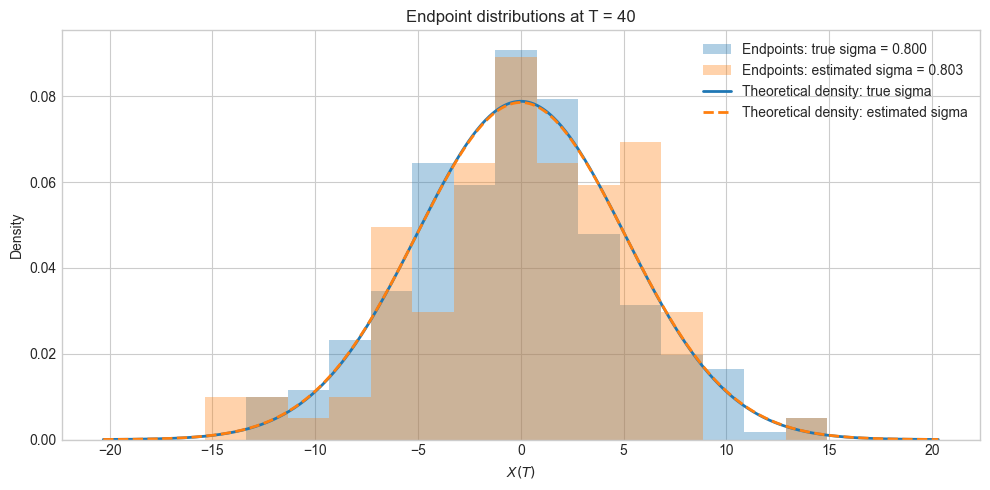

In [8]:
# Compare endpoint distributions at the same final time.
endpoints_true = np.array([path[-1] for time, path in paths_list])
endpoints_hat = np.array([path[-1] for time, path in paths_list_sigma_hat])
brownian_duration = paths_list[0][0][-1]
assert all(np.isclose(time[-1], brownian_duration) for time, path in paths_list_sigma_hat)

# Shared bin edges make the two histograms directly comparable.
bins = np.histogram_bin_edges(
    np.concatenate([endpoints_true, endpoints_hat]), bins=15
)
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(endpoints_true, bins=bins, density=True, alpha=0.35,
        color="C0", label=f"Endpoints: true sigma = {brownian_sigma_true:.3f}")
ax.hist(endpoints_hat, bins=bins, density=True, alpha=0.35,
        color="C1", label=f"Endpoints: estimated sigma = {brownian_sigma_hat:.3f}")

std_true = brownian_sigma_true * np.sqrt(brownian_duration)
std_hat = brownian_sigma_hat * np.sqrt(brownian_duration)
x = np.linspace(-4 * max(std_true, std_hat),
                4 * max(std_true, std_hat), 600)
for std, color, linestyle, label in [
    (std_true, "C0", "-", "Theoretical density: true sigma"),
    (std_hat, "C1", "--", "Theoretical density: estimated sigma"),
]:
    density = np.exp(-0.5 * (x / std)**2) / (std * np.sqrt(2 * np.pi))
    ax.plot(x, density, color=color, linestyle=linestyle, lw=2, label=label)

ax.set(title=f"Endpoint distributions at T = {brownian_duration:g}",
       xlabel="$X(T)$", ylabel="Density")
ax.legend()
fig.tight_layout()
plt.show()

**Reading the plot:** A bar’s height × its width gives the fraction of endpoints in that bin. For example, 0.08 × 2 = 16%. The smooth lines show the distributions predicted by the model.


## 2. Noisy harmonic oscillator

We use position $X_t$ and velocity $V_t$, governed by

$$dX_t=V_t\,dt, \qquad dV_t=-\omega_0^2X_t\,dt+\sigma\,dW_t.$$

The restoring force is $-\omega_0^2X_t$. This is **undamped**, so random forcing can increase the oscillator's energy over time. Add a term $-\gamma V_t\,dt$ if a stationary, damped oscillator is required.

The continuous undamped model has increasing expected energy because of the
random forcing. Explicit Euler introduces additional numerical energy growth:
without noise, each step multiplies the energy by
$1+\omega_0^2\Delta t^2$. The covariance recursion below describes the actual
Euler model; the sine-based variance formulas describe the continuous SDE.

In [9]:
def harmonic_oscillator(omega0, sigma, x0, v0, dt, n_steps, rng):
    """Simulate dX=V dt, dV=-omega0**2 X dt + sigma dW."""
    time = np.arange(n_steps + 1) * dt
    position = np.empty(n_steps + 1)
    velocity = np.empty(n_steps + 1)
    position[0], velocity[0] = x0, v0

    for i in range(n_steps):
        position[i + 1] = position[i] + velocity[i] * dt
        velocity[i + 1] = (
            velocity[i] - omega0**2 * position[i] * dt
            + sigma * np.sqrt(dt) * rng.normal()
        )

    return time, position, velocity

def oscillator_endpoint_distribution(omega0, sigma, T, x0=0.0, v0=0.0):
    """Return endpoint means and standard deviations: [position, velocity]."""
    angle = omega0 * T
    means = np.array([
        x0 * np.cos(angle) + (v0 / omega0) * np.sin(angle),
        -omega0 * x0 * np.sin(angle) + v0 * np.cos(angle),
    ])

    sin_term = np.sin(2 * angle) / (4 * omega0)
    variances = sigma**2 * np.array([
        (T / 2 - sin_term) / omega0**2,
        T / 2 + sin_term,
    ])
    standard_deviations = np.sqrt(variances)
    return means, standard_deviations


def normal_pdf(values, mean, std):
    """Evaluate a normal probability density at the supplied values."""
    standardized_values = (values - mean) / std
    bell_shape = np.exp(-0.5 * standardized_values**2)
    normalization = std * np.sqrt(2 * np.pi)
    return bell_shape / normalization


oscillator_omega0 = 1.0
oscillator_sigma_true = 0.30
oscillator_dt = 0.001
oscillator_n_steps = 50_000

oscillator_paths = []

for i in range(100):
    oscillator_time, position, velocity = harmonic_oscillator(
       oscillator_omega0, oscillator_sigma_true, x0=0.0, v0=0.0,
       dt=oscillator_dt, n_steps=oscillator_n_steps, rng=rng,
    )
    oscillator_paths.append((oscillator_time, position, velocity))


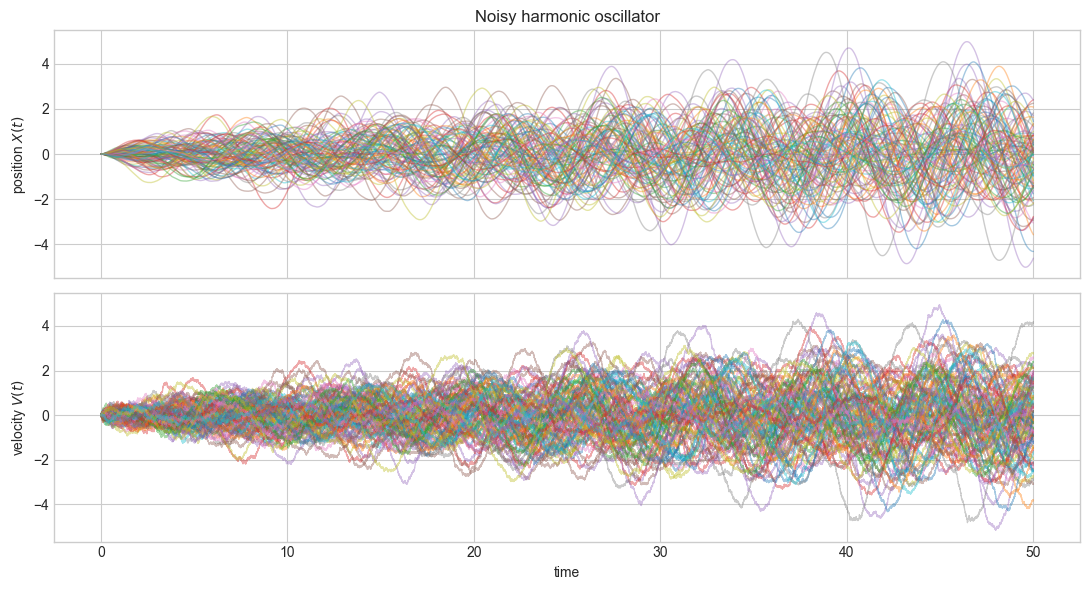

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].set(title="Noisy harmonic oscillator", ylabel="position $X(t)$")
axes[1].set(xlabel="time", ylabel="velocity $V(t)$")

for oscillator_time, position, velocity in oscillator_paths:
    axes[0].plot(oscillator_time, position, lw=1.0, alpha=0.4)
    axes[1].plot(oscillator_time, velocity, lw=0.9, alpha=0.4)

fig.tight_layout()
plt.show()

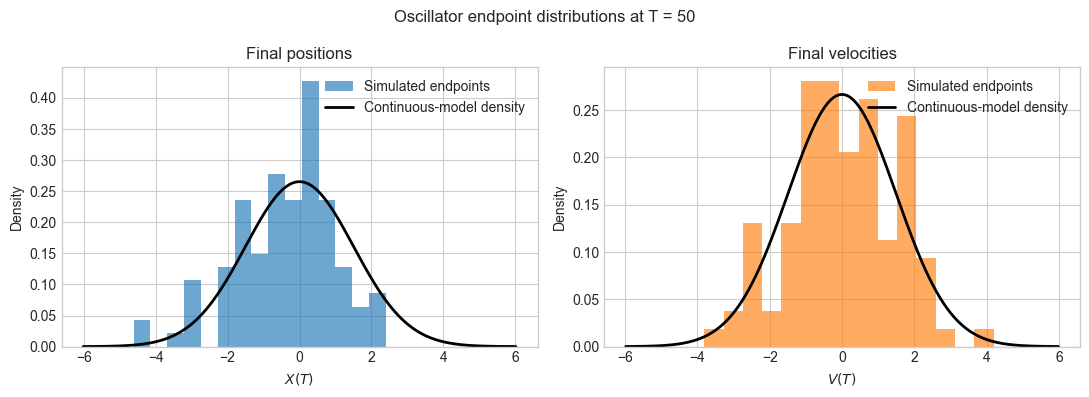

In [11]:
# Distributions of final position and velocity across all oscillator paths.
final_positions = np.array([pos[-1] for time, pos, vel in oscillator_paths])
final_velocities = np.array([vel[-1] for time, pos, vel in oscillator_paths])
final_time = oscillator_paths[0][0][-1]

# Predict the endpoint mean and covariance for the Euler--Maruyama model.
# State = [position, velocity]; noise enters velocity at each step.
transition = np.array([
    [1.0, oscillator_dt],
    [-oscillator_omega0**2 * oscillator_dt, 1.0],
])
noise_covariance = np.array([
    [0.0, 0.0],
    [0.0, oscillator_sigma_true**2 * oscillator_dt],
])
endpoint_mean = np.array([oscillator_paths[0][1][0],
                          oscillator_paths[0][2][0]])
endpoint_covariance = np.zeros((2, 2))
for _ in range(len(oscillator_paths[0][0]) - 1):
    endpoint_mean = transition @ endpoint_mean
    endpoint_covariance = (
        transition @ endpoint_covariance @ transition.T + noise_covariance
    )
endpoint_stds = np.sqrt(np.diag(endpoint_covariance))

# Continuous-model marginal distributions for the endpoint plot.
# Keep the discrete covariance above for the following 3D joint plot.
plot_means, plot_stds = oscillator_endpoint_distribution(
    oscillator_omega0, oscillator_sigma_true, final_time,
    x0=oscillator_paths[0][1][0], v0=oscillator_paths[0][2][0],
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, mean, std, color, title, xlabel in zip(
    axes, [final_positions, final_velocities], plot_means, plot_stds,
    ["C0", "C1"], ["Final positions", "Final velocities"], ["$X(T)$", "$V(T)$"],
):
    ax.hist(values, bins=15, density=True, alpha=0.65,
            color=color, label="Simulated endpoints")
    grid = np.linspace(min(values.min(), mean - 4 * std),
                       max(values.max(), mean + 4 * std), 500)
    density = normal_pdf(grid, mean, std)
    ax.plot(grid, density, color="black", lw=2, label="Continuous-model density")
    ax.set(title=title, xlabel=xlabel, ylabel="Density")
    ax.legend()
fig.suptitle(f"Oscillator endpoint distributions at T = {final_time:g}")
fig.tight_layout()
plt.show()


Each path contributes one final position and one final velocity. A bar’s height × its width gives the fraction of endpoints in that bin. The black curves show the normal distributions predicted by the continuous model, using the true sigma.


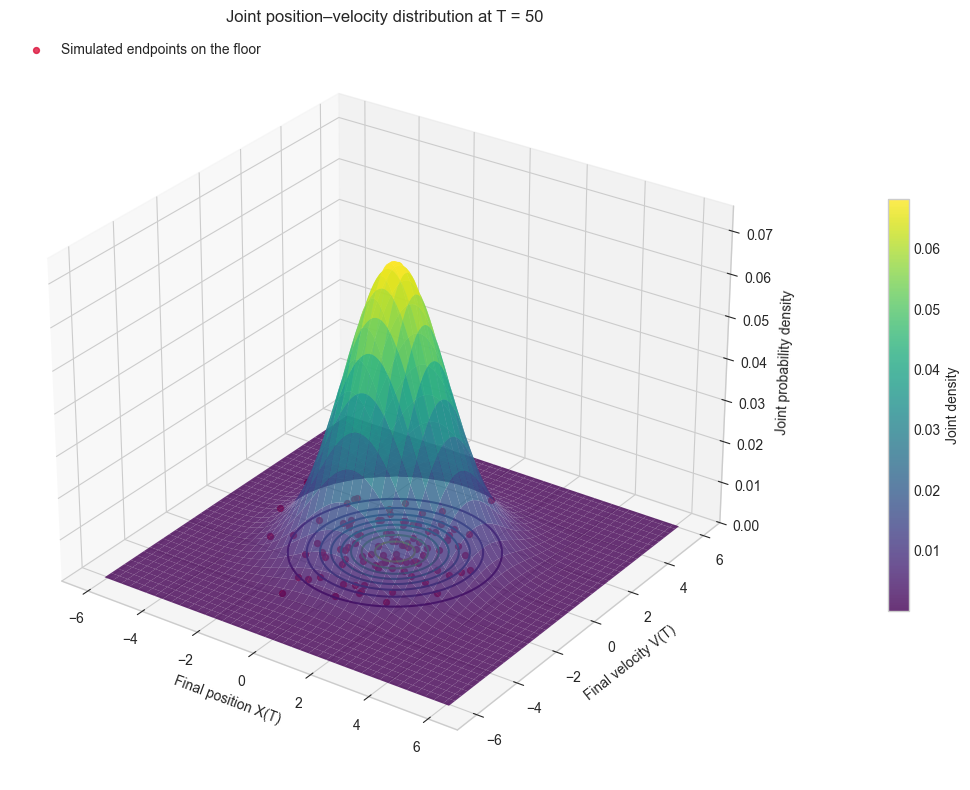

In [12]:
# Joint endpoint density: height is p(X(T), V(T)).
# Run the endpoint-distribution cell above first.
position_grid = np.linspace(endpoint_mean[0] - 4 * endpoint_stds[0],
                            endpoint_mean[0] + 4 * endpoint_stds[0], 120)
velocity_grid = np.linspace(endpoint_mean[1] - 4 * endpoint_stds[1],
                            endpoint_mean[1] + 4 * endpoint_stds[1], 120)
position_mesh, velocity_mesh = np.meshgrid(position_grid, velocity_grid)
centered_states = np.stack([position_mesh - endpoint_mean[0],
                           velocity_mesh - endpoint_mean[1]], axis=-1)
# Cholesky whitening includes the position-velocity correlation.
covariance_factor = np.linalg.cholesky(endpoint_covariance)
whitened_states = np.linalg.solve(
    covariance_factor, centered_states.reshape(-1, 2).T
).T.reshape(centered_states.shape)
joint_density = np.exp(-0.5 * np.sum(whitened_states**2, axis=-1)) / (
    2 * np.pi * np.prod(np.diag(covariance_factor))
)

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")
surface = ax.plot_surface(position_mesh, velocity_mesh, joint_density,
                          cmap="viridis", alpha=0.8, linewidth=0)
ax.contour(position_mesh, velocity_mesh, joint_density,
           zdir="z", offset=0, levels=8, cmap="viridis")
ax.scatter(final_positions, final_velocities,
           np.zeros_like(final_positions), color="crimson", s=18,
           alpha=0.8, label="Simulated endpoints on the floor", depthshade=False)
ax.set(xlabel="Final position X(T)", ylabel="Final velocity V(T)",
       zlabel="Joint probability density",
       title=f"Joint position–velocity distribution at T = {final_time:g}",
       zlim=(0, joint_density.max() * 1.1))
ax.view_init(elev=28, azim=-55)
ax.legend(loc="upper left")
fig.colorbar(surface, ax=ax, shrink=0.55, pad=0.12, label="Joint density")
fig.tight_layout()
plt.show()

# Probability is volume under the surface over a position–velocity region.
# Each red point is one path's final (position, velocity), not a whole trajectory.


### Deriving the harmonic-oscillator estimate of $\sigma$

We derive two related results: an estimator of the noise strength $\sigma$ from independent observed paths, and the theoretical distributions of final position and velocity.

Assume that $\omega_0>0$ is known, $\sigma\geq0$, and both position and velocity are observed. The model is

$$dX_t=V_t\,dt,\qquad dV_t=-\omega_0^2X_t\,dt+\sigma\,dW_t,$$

with fixed initial conditions $X_0=V_0=0$. Standard Brownian motion satisfies $W_0=0$ and $W_T\sim\mathcal N(0,T)$.

#### 1. Remove the restoring force to isolate the noise

Integrate the velocity equation over $[0,T]$:

$$\int_0^T dV_s=-\omega_0^2\int_0^T X_s\,ds+\sigma\int_0^T dW_s.$$

Since $\int_0^T dV_s=V_T-V_0$ and $\int_0^T dW_s=W_T-W_0=W_T$,

$$V_T-V_0=-\omega_0^2\int_0^T X_s\,ds+\sigma W_T.$$

The integral $\int_0^T X_s\,ds$ is the area under the position curve; it is not $X_T-X_0$. The latter equals $\int_0^T V_s\,ds$.

Define the corrected velocity change

$$R_T=V_T-V_0+\omega_0^2\int_0^T X_s\,ds.$$

Then

$$R_T=\sigma W_T\sim\mathcal N(0,\sigma^2T).$$

#### 2. Estimate $\sigma$ from the corrected changes

Because $\mathbb E[R_T]=0$,

$$\operatorname{Var}(R_T)=\mathbb E[R_T^2]-(\mathbb E[R_T])^2=\mathbb E[R_T^2]=\sigma^2T.$$

For $T>0$, rearrange to get

$$\sigma^2=\frac{\mathbb E[R_T^2]}{T}.$$

Each of the $n$ independent paths supplies a corrected change

$$r_i=v_T^{(i)}-v_0^{(i)}+\omega_0^2\int_0^T x_s^{(i)}\,ds.$$

Replace the theoretical expectation with the sample average:

$$\mathbb E[R_T^2]\approx\frac1n\sum_{i=1}^n r_i^2.$$

Therefore,

$$\boxed{\widehat{\sigma}=\sqrt{\frac1{nT}\sum_{i=1}^n\left(v_T^{(i)}-v_0^{(i)}+\omega_0^2\int_0^T x_s^{(i)}\,ds\right)^2}.}$$

Here $n$ is the number of paths, while $T$ is the elapsed time of each path. This is the maximum-likelihood estimate based on the $n$ corrected totals $r_i$; it is not the likelihood estimate using every observed time increment.

#### 3. Implement the integral for the Euler simulation

The notebook uses equally spaced observations $t_j=j\Delta t$, with $m$ steps and $T=m\Delta t$. Use the left-endpoint sum

$$\int_0^T x_s^{(i)}\,ds\approx\sum_{j=0}^{m-1}x_j^{(i)}\Delta t.$$

In code, this is `np.sum(pos[:-1] * np.diff(time))`. Thus each path contributes

$$r_i=v_m^{(i)}-v_0^{(i)}+\omega_0^2\sum_{j=0}^{m-1}x_j^{(i)}\Delta t.$$

This sum matches the simulation update

$$v_{j+1}^{(i)}-v_j^{(i)}=-\omega_0^2x_j^{(i)}\Delta t+\sigma\Delta W_j^{(i)}.$$

Summing that update over time shows that the corrected total is exactly $\sigma\sum_j\Delta W_j^{(i)}$ for the Euler model, up to floating-point error. Square each path's total, average across paths, divide by $T$, and take the square root. Do not take differences between endpoints of different paths.

#### 4. Solve for the position and velocity endpoints

To find the raw endpoint distributions, first consider a single velocity kick of size $a$ at time $s$. With no further forcing, its additional motion satisfies

$$X''(t)+\omega_0^2X(t)=0,\qquad X(s)=0,\quad V(s)=a.$$

The solution and its derivative are

$$X(t)=\frac{a}{\omega_0}\sin(\omega_0(t-s)),\qquad V(t)=a\cos(\omega_0(t-s)).$$

Thus a kick at time $s$ contributes a sine-weighted amount to position and a cosine-weighted amount to velocity at $T$. Since the oscillator is linear, add the responses to all Brownian kicks. For zero initial conditions,

$$X_T=\frac{\sigma}{\omega_0}\int_0^T\sin(\omega_0(T-s))\,dW_s,$$

$$V_T=\sigma\int_0^T\cos(\omega_0(T-s))\,dW_s.$$

These stochastic integrals have deterministic integrands, so they are jointly Gaussian with zero means.

#### 5. Calculate the endpoint variances

For a deterministic integrand $f$, the Brownian integral obeys

$$\mathbb E\left[\int_0^T f(s)\,dW_s\right]=0,\qquad \operatorname{Var}\left(\int_0^T f(s)\,dW_s\right)=\int_0^T f(s)^2\,ds.$$

The variance identity is Ito's isometry. It gives

$$\operatorname{Var}(X_T)=\frac{\sigma^2}{\omega_0^2}\int_0^T\sin^2(\omega_0(T-s))\,ds,$$

$$\operatorname{Var}(V_T)=\sigma^2\int_0^T\cos^2(\omega_0(T-s))\,ds.$$

Set $u=T-s$ and use $\sin^2 z=(1-\cos(2z))/2$ and $\cos^2 z=(1+\cos(2z))/2$:

$$\int_0^T\sin^2(\omega_0u)\,du=\frac T2-\frac{\sin(2\omega_0T)}{4\omega_0},$$

$$\int_0^T\cos^2(\omega_0u)\,du=\frac T2+\frac{\sin(2\omega_0T)}{4\omega_0}.$$

Therefore the marginal endpoint distributions are

$$\boxed{X_T\sim\mathcal N\left(0,\frac{\sigma^2}{\omega_0^2}\left[\frac T2-\frac{\sin(2\omega_0T)}{4\omega_0}\right]\right),}$$

$$\boxed{V_T\sim\mathcal N\left(0,\sigma^2\left[\frac T2+\frac{\sin(2\omega_0T)}{4\omega_0}\right]\right).}$$

Position and velocity are generally correlated; these formulas describe their separate marginal distributions, not independence.

#### 6. Connect the distributions to the plotted PDFs

For either endpoint, let $s_T$ be the square root of its variance above. Its normal probability density is

$$p(z)=\frac1{s_T\sqrt{2\pi}}\exp\left(-\frac{z^2}{2s_T^2}\right).$$

In the comparison plot, the sine terms enter through `std = sigma * unit_stds[component]`. The mean is zero, and substituting either the true or estimated $\sigma$ gives the corresponding theoretical curve.

These sine-based endpoint distributions are exact for the continuous oscillator. Euler--Maruyama approximates that model, so the simulated endpoint distributions differ slightly. The covariance recursion used elsewhere in the notebook instead gives exact endpoint distributions for the discrete Euler updates.


In [13]:
oscillator_duration = oscillator_n_steps * oscillator_dt
corrected_totals = np.array([
    vel[-1] - vel[0]
    + oscillator_omega0**2 * np.sum(pos[:-1] * np.diff(time))
    for time, pos, vel in oscillator_paths
])
oscillator_sigma_hat = np.sqrt(np.mean(corrected_totals**2) / oscillator_duration)
print(f"Oscillator corrected-total estimate ({len(oscillator_paths)} paths): {oscillator_sigma_hat:.10f}")

Oscillator corrected-total estimate (100 paths): 0.2596198521


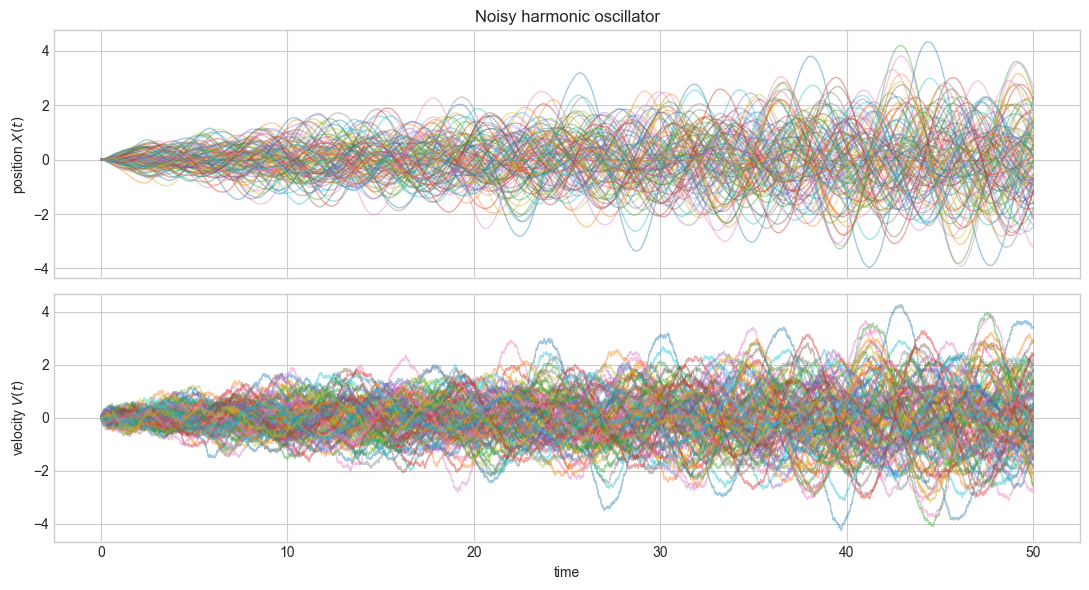

In [14]:
oscillator_paths_sigma_hat = []

for i in range(100):
    oscillator_time, position, velocity = harmonic_oscillator(
       oscillator_omega0, oscillator_sigma_hat, x0=0.0, v0=0.0,
       dt=oscillator_dt, n_steps=oscillator_n_steps, rng=rng,
    )
    oscillator_paths_sigma_hat.append((oscillator_time, position, velocity))

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].set(title="Noisy harmonic oscillator", ylabel="position $X(t)$")
axes[1].set(xlabel="time", ylabel="velocity $V(t)$")

for oscillator_time, position, velocity in oscillator_paths_sigma_hat:
    axes[0].plot(oscillator_time, position, lw=1.0, alpha=0.4)
    axes[1].plot(oscillator_time, velocity, lw=0.9, alpha=0.4)

fig.tight_layout()
plt.show()

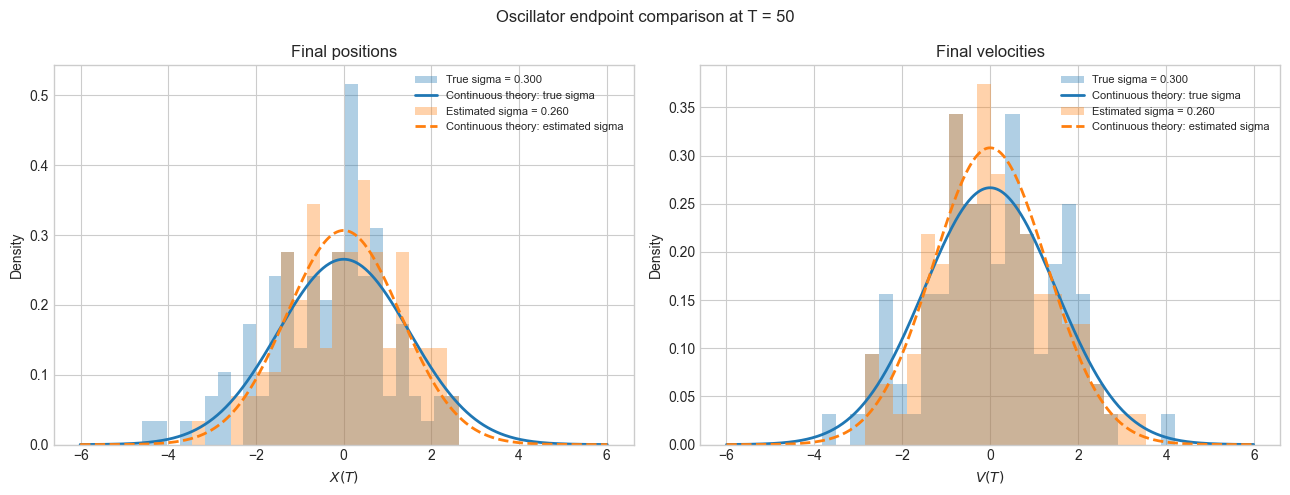

In [15]:
# Compare oscillator endpoints using continuous-model distributions.
true_endpoints = np.column_stack((final_positions, final_velocities))
hat_endpoints = np.array([
    [pos[-1], vel[-1]]
    for time, pos, vel in oscillator_paths_sigma_hat
])

comparison_mean, true_stds = oscillator_endpoint_distribution(
    oscillator_omega0, oscillator_sigma_true, final_time,
    x0=oscillator_paths[0][1][0], v0=oscillator_paths[0][2][0],
)
_, hat_stds = oscillator_endpoint_distribution(
    oscillator_omega0, oscillator_sigma_hat, final_time,
    x0=oscillator_paths_sigma_hat[0][1][0],
    v0=oscillator_paths_sigma_hat[0][2][0],
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for component, ax in enumerate(axes):
    combined = np.concatenate([
        true_endpoints[:, component],
        hat_endpoints[:, component],
    ])
    bins = np.histogram_bin_edges(combined, bins=25)
    mean = comparison_mean[component]
    max_std = max(true_stds[component], hat_stds[component])
    grid = np.linspace(
        min(combined.min(), mean - 4 * max_std),
        max(combined.max(), mean + 4 * max_std),
        500,
    )

    for endpoints, sigma, stds, color, linestyle, label in [
        (true_endpoints, oscillator_sigma_true, true_stds, "C0", "-", "True"),
        (hat_endpoints, oscillator_sigma_hat, hat_stds, "C1", "--", "Estimated"),
    ]:
        ax.hist(
            endpoints[:, component],
            bins=bins, density=True, alpha=0.35, color=color,
            label=f"{label} sigma = {sigma:.3f}",
        )

        std = stds[component]
        density = normal_pdf(grid, mean, std)
        ax.plot(
            grid, density, color=color, linestyle=linestyle,
            lw=2, label=f"Continuous theory: {label.lower()} sigma",
        )

    ax.set(
        title=["Final positions", "Final velocities"][component],
        xlabel=["$X(T)$", "$V(T)$"][component],
        ylabel="Density",
    )
    ax.legend(fontsize=8)

fig.suptitle(f"Oscillator endpoint comparison at T = {final_time:g}")
fig.tight_layout()
plt.show()

Blue uses the true sigma; orange uses the estimated sigma. Bars show simulated endpoints, and lines show model predictions. A bar’s height × its width gives the fraction of endpoints in its bin. With only 100 paths per experiment, histogram differences also reflect random sampling.


True diffusion: sigma=0.3000000000, mean=0.001003, std=1.000007
Corrected-total estimate: sigma=0.2596198521, mean=0.001159, std=1.155544


Pooled-increment estimate: sigma=0.3000023767, mean=0.001003, std=0.999999


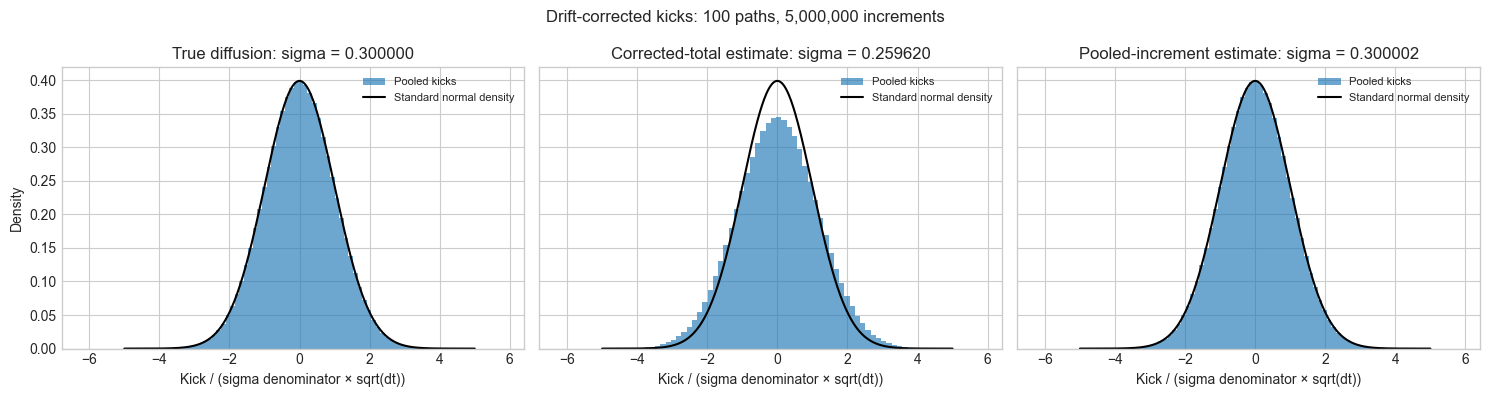

In [16]:
# Remove the spring drift from every velocity increment of the original paths.
all_oscillator_innovations = np.concatenate([
    np.diff(vel) + oscillator_omega0**2 * pos[:-1] * oscillator_dt
    for time, pos, vel in oscillator_paths
])
oscillator_increment_sigma_hat = np.sqrt(
    np.mean(all_oscillator_innovations**2) / oscillator_dt
)
# Compare three explicitly labeled denominators; totals use one value per path.
innovation_scales = [
    ("True diffusion", oscillator_sigma_true),
    ("Corrected-total estimate", oscillator_sigma_hat),
    ("Pooled-increment estimate", oscillator_increment_sigma_hat),
]
innovation_diagnostics = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
grid = np.linspace(-5, 5, 500)
for ax, (label, scale) in zip(axes, innovation_scales):
    standardized = all_oscillator_innovations / (scale * np.sqrt(oscillator_dt))
    diagnostic = {
        "standardization": label,
        "sigma_denominator": float(scale),
        "n_increments": int(standardized.size),
        "mean": float(standardized.mean()),
        "std": float(standardized.std()),
    }
    innovation_diagnostics.append(diagnostic)
    ax.hist(standardized, bins=80, density=True, alpha=0.65, label="Pooled kicks")
    ax.plot(grid, np.exp(-grid**2 / 2) / np.sqrt(2 * np.pi),
            color="black", label="Standard normal density")
    ax.set(title=f"{label}: sigma = {scale:.6f}",
           xlabel="Kick / (sigma denominator × sqrt(dt))")
    ax.legend(fontsize=8)
    print(f"{label}: sigma={scale:.10f}, "
          f"mean={diagnostic['mean']:.6f}, std={diagnostic['std']:.6f}")
axes[0].set_ylabel("Density")
fig.suptitle(f"Drift-corrected kicks: {len(oscillator_paths)} paths, "
             f"{all_oscillator_innovations.size:,} increments")
fig.tight_layout()
plt.show()
# These moments must reflect the explicitly supplied scale.
np.testing.assert_allclose(
    innovation_diagnostics[1]["std"] / innovation_diagnostics[0]["std"],
    oscillator_sigma_true / oscillator_sigma_hat,
)

Each panel uses the same drift-corrected increments with a different,
explicitly labeled diffusion denominator. Scaling by the true diffusion checks
the simulated noise. Scaling by the corrected-total estimate checks that
estimate's calibration. The pooled-increment estimate is fitted to these same
increments, so its near-unit standardized second moment follows by construction
and is not independent validation. A histogram alone does not test independence.

### Endpoint estimates under the continuous and Euler models

Fit the Brownian endpoints using their own duration. For the oscillator,
compare the continuous-model endpoint variance with the exact Euler covariance
already computed above. Both fits use the known zero endpoint mean. This
comparison measures the numerical-model effect on this estimator in this
particular dataset; it does not establish a ranking across repeated datasets.

In [17]:
_, brownian_endpoint_std = norm.fit(final_values, floc=0)
brownian_endpoint_sigma_mle = brownian_endpoint_std / np.sqrt(brownian_duration)
np.testing.assert_allclose(brownian_endpoint_sigma_mle, brownian_endpoint_sigma_hat)

continuous_position_variance_factor = (
    oscillator_duration / 2
    - np.sin(2 * oscillator_omega0 * oscillator_duration) / (4 * oscillator_omega0)
) / oscillator_omega0**2
_, oscillator_endpoint_std = norm.fit(final_positions, floc=0)
oscillator_sigma_mle = oscillator_endpoint_std / np.sqrt(continuous_position_variance_factor)
discrete_position_variance_factor = endpoint_covariance[0, 0] / oscillator_sigma_true**2
oscillator_discrete_sigma_mle = oscillator_endpoint_std / np.sqrt(discrete_position_variance_factor)
print(f"Continuous position variance factor: {continuous_position_variance_factor:.10f}")
print(f"Euler position variance factor: {discrete_position_variance_factor:.10f}")
print(f"Endpoint estimate change (Euler / continuous - 1): "
      f"{100 * (oscillator_discrete_sigma_mle / oscillator_sigma_mle - 1):.6f}%")

Continuous position variance factor: 25.1265914103
Euler position variance factor: 25.7686127697
Endpoint estimate change (Euler / continuous - 1): -1.253601%


In [18]:
print(f"Brownian endpoint sigma (T={brownian_duration:g}): {brownian_endpoint_sigma_mle:.10f}")
print(f"Oscillator endpoint sigma, continuous variance: {oscillator_sigma_mle:.10f}")
print(f"Oscillator endpoint sigma, Euler variance: {oscillator_discrete_sigma_mle:.10f}")
print(f"Oscillator pooled-increment sigma: {oscillator_increment_sigma_hat:.10f}")

Brownian endpoint sigma (T=40): 0.8111029545
Oscillator endpoint sigma, continuous variance: 0.2881263237
Oscillator endpoint sigma, Euler variance: 0.2845143706
Oscillator pooled-increment sigma: 0.3000023767


In [19]:
from experiment_artifacts import export_results

likelihood_estimates = [
    {"model": "Brownian", "estimator": "endpoint", "sigma_true": brownian_sigma_true,
     "sigma_estimate": float(brownian_endpoint_sigma_mle), "duration": float(brownian_duration),
     "n_paths": len(paths_list), "n_gaussian_values": len(paths_list)},
    {"model": "Brownian", "estimator": "increment_last_path", "sigma_true": brownian_sigma_true,
     "sigma_estimate": float(brownian_sigma_hat), "duration": float(brownian_duration),
     "n_paths": 1, "n_gaussian_values": int(brownian_increments.size)},
    {"model": "Oscillator", "estimator": "corrected_total", "sigma_true": oscillator_sigma_true,
     "sigma_estimate": float(oscillator_sigma_hat), "duration": float(oscillator_duration),
     "n_paths": len(oscillator_paths), "n_gaussian_values": len(oscillator_paths)},
    {"model": "Oscillator", "estimator": "endpoint_continuous", "sigma_true": oscillator_sigma_true,
     "sigma_estimate": float(oscillator_sigma_mle), "duration": float(oscillator_duration),
     "n_paths": len(oscillator_paths), "n_gaussian_values": len(oscillator_paths)},
    {"model": "Oscillator", "estimator": "endpoint_euler", "sigma_true": oscillator_sigma_true,
     "sigma_estimate": float(oscillator_discrete_sigma_mle), "duration": float(oscillator_duration),
     "n_paths": len(oscillator_paths), "n_gaussian_values": len(oscillator_paths)},
    {"model": "Oscillator", "estimator": "pooled_increments", "sigma_true": oscillator_sigma_true,
     "sigma_estimate": float(oscillator_increment_sigma_hat), "duration": float(oscillator_duration),
     "n_paths": len(oscillator_paths), "n_gaussian_values": int(all_oscillator_innovations.size)},
]
for row in likelihood_estimates:
    row["relative_error_percent"] = 100 * abs(row["sigma_estimate"] - row["sigma_true"]) / row["sigma_true"]
export_results(
    "likelihood_calc.ipynb",
    {"diffusion_estimates": likelihood_estimates, "innovation_diagnostics": innovation_diagnostics},
    seeds={"numpy_stream": 1},
    settings={"brownian_dt": brownian_dt, "oscillator_dt": oscillator_dt,
              "continuous_position_variance_factor": float(continuous_position_variance_factor),
              "euler_position_variance_factor": float(discrete_position_variance_factor)},
)

Exported result tables and execution environment to /Users/pasha/Desktop/master/master_thesis/sandbox/experiment_results/likelihood_calc


PosixPath('/Users/pasha/Desktop/master/master_thesis/sandbox/experiment_results/likelihood_calc')